# CAREMap · 02 Scoring (v1)

Stage 5 of the [project plan](https://claude.ai/artifact/AYBNdGqtaB2AcdvZ3tQKrc). Builds the childcare score, the housing score, the combined score and the priority tiers, using the decisions from Stage 1 and the exploratory analysis:

| Decision | Why |
|---|---|
| Rank metro and nonmetro counties separately (USDA codes 1-3 vs 4-9) | Stage 1 choice; the groups differ a lot on every measure |
| Percentile ranks, not z-scores | Counts and several ratios are heavily skewed |
| Smooth small-county rates (empirical Bayes) before ranking | Tiny counties produce extreme values from small samples |
| Childcare score from kids under 5 per childcare worker, run twice (0 and 2 withheld businesses) | 928 counties' business data is withheld; rural ranks depend on it |
| Housing score = half families (rent burden + home price-to-income), half providers (2-bedroom rent as a share of a childcare worker's pay); rental vacancy dropped | Stage 1: housing for families and providers equally; vacancy looked like noise in notebook 01 |
| Combined score = geometric mean, so a county must be high on both | The project is about where the two problems overlap |
| Screens, not scored: minimum kids under 5; population trend shown as a flag; college counties flagged | Feasibility and data-quality context |

Output: `data/processed/county_scores_v1.csv`, which feeds the v1 map.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

df = pd.read_csv(ROOT / "data/processed/county_v1_join.csv", dtype={"GEOID": str})
df["group"] = np.where(df["metro"] == True, "Metro", "Nonmetro")
print(f"{len(df):,} counties")

3,144 counties


## Settings

Every judgment call is a named setting here, so it can be changed in one place and shown on the methods page.

In [2]:
MIN_KIDS_UNDER5 = 100        # below this, too few young children to judge or to sustain home-based providers
COLLEGE_FLAG_SHARE = 0.15    # share of residents 3+ enrolled in college or grad school
GROWTH_BANDS = (-2.0, 2.0)   # population change 2020-2025, % : below = declining, above = growing
TOP_SHARE = 0.25             # "top 25%" used for tiers
N_WEIGHT_DRAWS = 1000        # random weightings for the stability check
RNG = np.random.default_rng(42)

## 1. Screens and flags

In [3]:
df["screened_out"] = df["kids_under5"] < MIN_KIDS_UNDER5
df["college_county"] = df["college_share"] >= COLLEGE_FLAG_SHARE
df["pop_trend"] = pd.cut(df["pop_change_pct"], [-np.inf, GROWTH_BANDS[0], GROWTH_BANDS[1], np.inf],
                         labels=["Declining", "Stable", "Growing"])

print(f"Screened out (fewer than {MIN_KIDS_UNDER5} kids under 5): {df['screened_out'].sum()}")
print(df[df["screened_out"]].groupby("group").size().rename("screened out"))
print(f"\nCollege counties (>= {COLLEGE_FLAG_SHARE:.0%} enrolled): {df['college_county'].sum()}")
print(df[df["college_county"]].nlargest(10, "college_share")[["county_name", "USPS", "college_share"]].to_string(index=False))

s = df[~df["screened_out"]].copy()
print(f"\nCounties scored: {len(s):,}")

Screened out (fewer than 100 kids under 5): 109
group
Metro         5
Nonmetro    104
Name: screened out, dtype: int64

College counties (>= 15% enrolled): 71
      county_name USPS  college_share
   Lexington city   VA       0.477459
   Madison County   ID       0.434576
Williamsburg city   VA       0.411671
     Radford city   VA       0.396054
   Whitman County   WA       0.326621
      Clay County   SD       0.307123
Harrisonburg city   VA       0.304270
   Watauga County   NC       0.300730
     Story County   IA       0.299194
 Oktibbeha County   MS       0.297918

Counties scored: 3,035


## 2. Smoothing small-county rates (empirical Bayes)

**What it does:** pulls each county's rate toward its group's average, more strongly when the county's sample is small. A county with 40 renters and 100% burdened moves a lot; a county with 40,000 renters barely moves.

**How:** the group's average rate is the prior. Its strength `m` is estimated from the data (method of moments): how much counties really vary, beyond what small samples alone would cause. Smoothed rate = (count + m × group rate) / (base + m).

- Rent burden: burdened renter households out of renter households.
- Kids per worker: kids under 5 per childcare worker. This also handles counties with zero providers, which would otherwise divide by zero.

In [4]:
def eb_smooth(count, base, kind):
    """Empirical Bayes shrinkage toward the pooled rate.
    kind='proportion' (binomial noise) or 'rate' (Poisson noise per unit of base)."""
    count, base = count.astype(float), base.astype(float)
    ok = base > 0
    r0 = count.sum() / base.sum()
    raw = count[ok] / base[ok]
    noise = r0 * (1 - r0) / base[ok] if kind == "proportion" else r0 / base[ok]
    between = max(raw.var() - noise.mean(), 1e-12)
    m = (r0 * (1 - r0) / between - 1) if kind == "proportion" else r0 / between
    m = max(m, 0.0)
    return (count + m * r0) / (base + m), m


s["burdened"] = s[["rent_pct_30_35", "rent_pct_35_40", "rent_pct_40_50", "rent_pct_50plus"]].sum(axis=1)
s["renters_computed"] = s["renters_total"] - s["rent_pct_not_computed"]

# withheld counties: 0 businesses (low supply) or 2 businesses x median small-county staff (high supply)
published = s[~s["cbp_withheld_0to2"] & (s["cbp_estab"] <= 5)]
staff_per_estab = (published["cbp_emp"] / published["cbp_estab"]).groupby(published["group"]).median()
withheld = s["cbp_withheld_0to2"]
s["workers_low"] = s["cbp_emp"].where(~withheld, 0) + s["nes_estab"]
s["workers_high"] = s["cbp_emp"].where(~withheld, 2 * s["group"].map(staff_per_estab)) + s["nes_estab"]

strengths = []
for g, idx in s.groupby("group").groups.items():
    sub = s.loc[idx]
    s.loc[idx, "rent_burden_eb"], m1 = eb_smooth(sub["burdened"], sub["renters_computed"], "proportion")
    s.loc[idx, "kpw_low_eb"], m2 = eb_smooth(sub["kids_under5"], sub["workers_low"], "rate")
    s.loc[idx, "kpw_high_eb"], m3 = eb_smooth(sub["kids_under5"], sub["workers_high"], "rate")
    strengths.append({"group": g, "rent_burden_m": round(m1, 1), "kids_per_worker_low_m": round(m2, 1),
                      "kids_per_worker_high_m": round(m3, 1)})
pd.DataFrame(strengths)

,group,rent_burden_m,kids_per_worker_low_m,kids_per_worker_high_m
0,Metro,40.5,0.1,0.3
1,Nonmetro,24.3,0.0,0.2


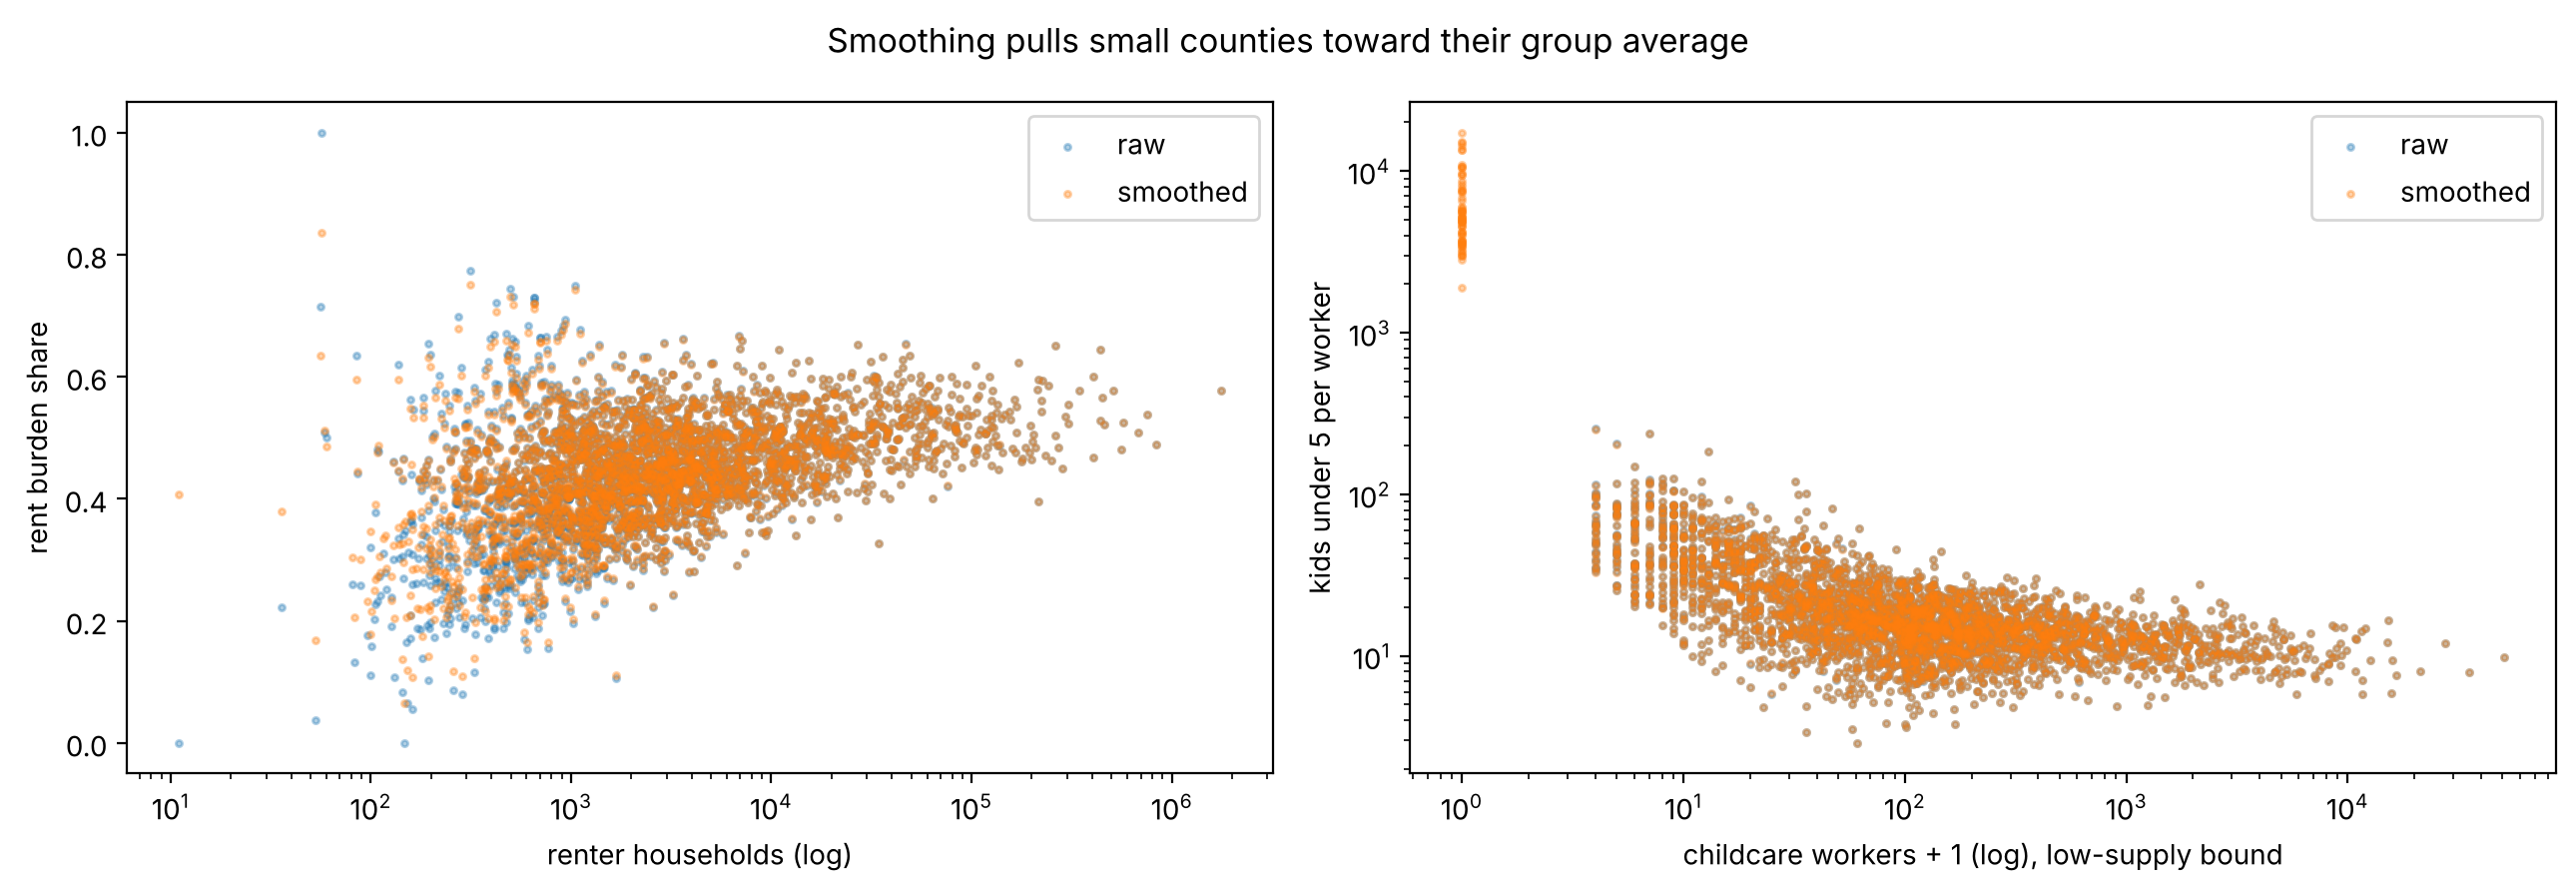

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
raw_rb = s["burdened"] / s["renters_computed"]
axes[0].scatter(s["renters_computed"], raw_rb, s=5, alpha=0.35, label="raw")
axes[0].scatter(s["renters_computed"], s["rent_burden_eb"], s=5, alpha=0.35, label="smoothed")
axes[0].set_xscale("log"); axes[0].set_xlabel("renter households (log)"); axes[0].set_ylabel("rent burden share")
axes[0].legend()
raw_kpw = s["kids_under5"] / s["workers_low"].replace(0, np.nan)
axes[1].scatter(s["workers_low"] + 1, raw_kpw, s=5, alpha=0.35, label="raw")
axes[1].scatter(s["workers_low"] + 1, s["kpw_low_eb"], s=5, alpha=0.35, label="smoothed")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("childcare workers + 1 (log), low-supply bound"); axes[1].set_ylabel("kids under 5 per worker")
axes[1].legend()
fig.suptitle("Smoothing pulls small counties toward their group average")
fig.tight_layout()
fig.savefig(FIG / "02_smoothing.png", dpi=150)
plt.show()

## 2b. Provider housing: can a childcare worker afford local rent?

A year of HUD's 2-bedroom Fair Market Rent divided by the median annual pay of childcare workers in the county's BLS area. Above 0.30 means rent alone would take more than 30% of pay (HUD's cost-burden line). Wages are for employees, so this stands in for what home-based providers earn.

In [6]:
print(f"Counties where a median-paid childcare worker would be rent-burdened (> 30%): "
      f"{(df['provider_rent_share'] > 0.30).mean():.0%}")
print(f"Counties above 50% of pay: {(df['provider_rent_share'] > 0.50).mean():.0%}")
print(f"Counties using a state-median wage (BLS publishes none for their area): {int(df['wage_imputed'].sum())}")
df.groupby("group")["provider_rent_share"].describe().round(3)

Counties where a median-paid childcare worker would be rent-burdened (> 30%): 100%
Counties above 50% of pay: 37%
Counties using a state-median wage (BLS publishes none for their area): 21


,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
Metro,1186.0,0.561,0.117,0.319,0.474,0.554,0.627,1.342
Nonmetro,1958.0,0.446,0.072,0.314,0.401,0.424,0.479,0.988


## 3. Scores

All percentiles are within the county's own group (metro or nonmetro), 0-100, where 100 = most need.

- **Childcare score**: percentile of smoothed kids per worker, under each bound.
- **Housing score**: half the family side (average of the rent burden and price-to-income percentiles) and half the provider side (percentile of 2-bedroom rent as a share of a childcare worker's median pay), re-ranked to 0-100.
- **Combined score**: geometric mean √(childcare × housing). A county high on only one problem can't score high.

In [7]:
def pct(col):
    return s.groupby("group")[col].rank(pct=True) * 100

s["rent_burden_pctile"] = pct("rent_burden_eb")
s["price_to_income_pctile"] = pct("price_to_income")
s["provider_rent_pctile"] = pct("provider_rent_share")
s["family_housing"] = s[["rent_burden_pctile", "price_to_income_pctile"]].mean(axis=1)
s["housing_raw"] = 0.5 * s["family_housing"] + 0.5 * s["provider_rent_pctile"]
s["housing_score"] = pct("housing_raw")

for b in ("low", "high"):
    s[f"childcare_score_{b}"] = pct(f"kpw_{b}_eb")
    s[f"combined_{b}"] = np.sqrt(s[f"childcare_score_{b}"] * s["housing_score"])

s["childcare_score"] = (s["childcare_score_low"] + s["childcare_score_high"]) / 2
s["combined_score"] = (s["combined_low"] + s["combined_high"]) / 2
s["rank_in_group"] = s.groupby("group")["combined_score"].rank(ascending=False, method="min").astype(int)
s["withheld_range"] = (s["combined_low"] - s["combined_high"]).abs()
s[["childcare_score", "housing_score", "combined_score", "withheld_range"]].describe().round(1)

,childcare_score,housing_score,combined_score,withheld_range
count,3035.0,3035.0,3035.0,3035.0
mean,50.0,50.0,44.3,6.7
std,26.9,28.9,21.4,7.9
min,0.1,0.1,0.6,0.0
25%,27.5,25.0,27.5,1.8
50%,50.8,50.1,44.1,4.0
75%,72.8,75.0,61.2,9.3
max,99.3,100.0,96.2,76.7


## 4. Tiers

Per bound: **High** = childcare and housing scores both in the group's top 25%; **Medium** = combined score in the top 25% otherwise; **Low** = the rest.

The final tier is the *lower* of the two bounds, so a county is only called High if it's High whether its withheld businesses number 0 or 2. Counties whose tier depends on the bound get `tier_uncertain = True`.

In [8]:
TIER_ORDER = {"Low": 0, "Medium": 1, "High": 2}

def tiers(b):
    cut = 100 * (1 - TOP_SHARE)
    combined_cut = s.groupby("group")[f"combined_{b}"].transform(lambda x: x.quantile(1 - TOP_SHARE))
    both_high = (s[f"childcare_score_{b}"] >= cut) & (s["housing_score"] >= cut)
    return np.select([both_high, s[f"combined_{b}"] >= combined_cut], ["High", "Medium"], "Low")

s["tier_low"], s["tier_high"] = tiers("low"), tiers("high")
s["tier"] = np.where(s["tier_low"].map(TIER_ORDER) <= s["tier_high"].map(TIER_ORDER), s["tier_low"], s["tier_high"])
s["tier_uncertain"] = s["tier_low"] != s["tier_high"]

pd.crosstab(s["group"], s["tier"], margins=True)

tier,High,Low,Medium,All
group,,,,
Metro,25,908,248,1181
Nonmetro,38,1510,306,1854
All,63,2418,554,3035


In [9]:
print("Tier depends on the withheld-business assumption:")
print(s.groupby("group")["tier_uncertain"].agg(["sum", "mean"]).round(3))

Tier depends on the withheld-business assumption:
          sum   mean
group               
Metro      63  0.053
Nonmetro  324  0.175


## 5. Stability across weightings (research question 3)

The combined score above weights childcare and housing equally, families and providers equally, and rent burden and price-to-income equally. Here 1,000 random weightings are drawn (childcare weight 30-70%; family vs. provider weight 30-70%; rent burden vs. price-to-income anywhere from 0-100%), and both bounds are used. `stable_share` is how often a county lands in its group's top 25%. A county at 90%+ is a top candidate under almost any reasonable weighting.

In [10]:
hits = pd.Series(0.0, index=s.index)
for _ in range(N_WEIGHT_DRAWS):
    w_child = RNG.uniform(0.3, 0.7)
    w_rent = RNG.uniform(0, 1)
    w_family = RNG.uniform(0.3, 0.7)
    b = RNG.choice(["low", "high"])
    housing = s.groupby("group").apply(
        lambda g: (w_family * (w_rent * g["rent_burden_pctile"] + (1 - w_rent) * g["price_to_income_pctile"])
                   + (1 - w_family) * g["provider_rent_pctile"]).rank(pct=True) * 100,
        include_groups=False,
    ).reset_index(level=0, drop=True)
    combined = s[f"childcare_score_{b}"] ** w_child * housing ** (1 - w_child)
    cut = combined.groupby(s["group"]).transform(lambda x: x.quantile(1 - TOP_SHARE))
    hits += (combined >= cut)
s["stable_share"] = hits / N_WEIGHT_DRAWS

print("Counties in the top 25% under 90%+ of weightings:")
print(s[s["stable_share"] >= 0.9].groupby("group").size())

Counties in the top 25% under 90%+ of weightings:
group
Metro       174
Nonmetro    197
dtype: int64


## 6. Top counties by group

In [11]:
cols = ["rank_in_group", "county_name", "USPS", "kids_under5", "childcare_score", "housing_score",
        "combined_score", "tier", "tier_uncertain", "stable_share", "pop_trend", "college_county"]
for g in ("Metro", "Nonmetro"):
    print(f"\n{g}: top 15")
    display(s[s["group"] == g].sort_values("rank_in_group")[cols].head(15).round(1))


Metro: top 15


,rank_in_group,county_name,USPS,kids_under5,childcare_score,housing_score,combined_score,tier,tier_uncertain,stable_share,pop_trend,college_county
552,1,Maui County,HI,8821,93.4,99.2,96.2,High,False,1.0,Declining,False
500,2,Pickens County,GA,1598,95.5,93.2,94.3,High,False,1.0,Growing,False
2805,3,Washington County,UT,11732,93.0,93.7,93.4,High,False,1.0,Growing,False
213,4,Monterey County,CA,28601,88.6,98.1,93.2,High,False,1.0,Stable,False
2324,5,Beaufort County,SC,9020,86.2,96.4,91.1,High,False,1.0,Growing,False
2843,6,Clarke County,VA,628,84.1,98.5,90.9,High,False,1.0,Growing,False
549,7,Honolulu County,HI,56781,81.2,99.5,89.9,High,False,1.0,Declining,False
1918,8,Currituck County,NC,1509,97.5,80.3,88.4,High,False,1.0,Growing,False
367,9,Okaloosa County,FL,13347,84.3,92.7,88.4,High,False,1.0,Growing,False
3,10,Bibb County,AL,1092,94.9,82.2,88.3,High,False,1.0,Stable,False



Nonmetro: top 15


,rank_in_group,county_name,USPS,kids_under5,childcare_score,housing_score,combined_score,tier,tier_uncertain,stable_share,pop_trend,college_county
2674,1,Llano County,TX,911,92.9,98.8,95.7,High,False,1.0,Growing,False
1749,2,Churchill County,NV,1535,89.9,94.2,91.9,High,False,1.0,Stable,False
2719,3,Reeves County,TX,876,97.4,86.7,91.9,High,False,1.0,Declining,False
248,4,Archuleta County,CO,530,86.6,96.9,91.5,High,False,1.0,Growing,False
2596,5,Erath County,TX,2475,84.5,99.3,91.5,High,False,1.0,Growing,True
551,6,Kauai County,HI,3964,84.3,99.5,91.5,Medium,True,1.0,Stable,False
2617,7,Grimes County,TX,1656,87.9,94.9,91.3,High,False,1.0,Growing,False
1101,8,Simpson County,KY,1070,91.6,90.2,90.9,High,False,1.0,Growing,False
1172,9,Vernon Parish,LA,3756,95.3,86.0,90.5,High,False,1.0,Declining,False
2711,10,Polk County,TX,2624,85.9,94.8,90.1,High,False,1.0,Growing,False


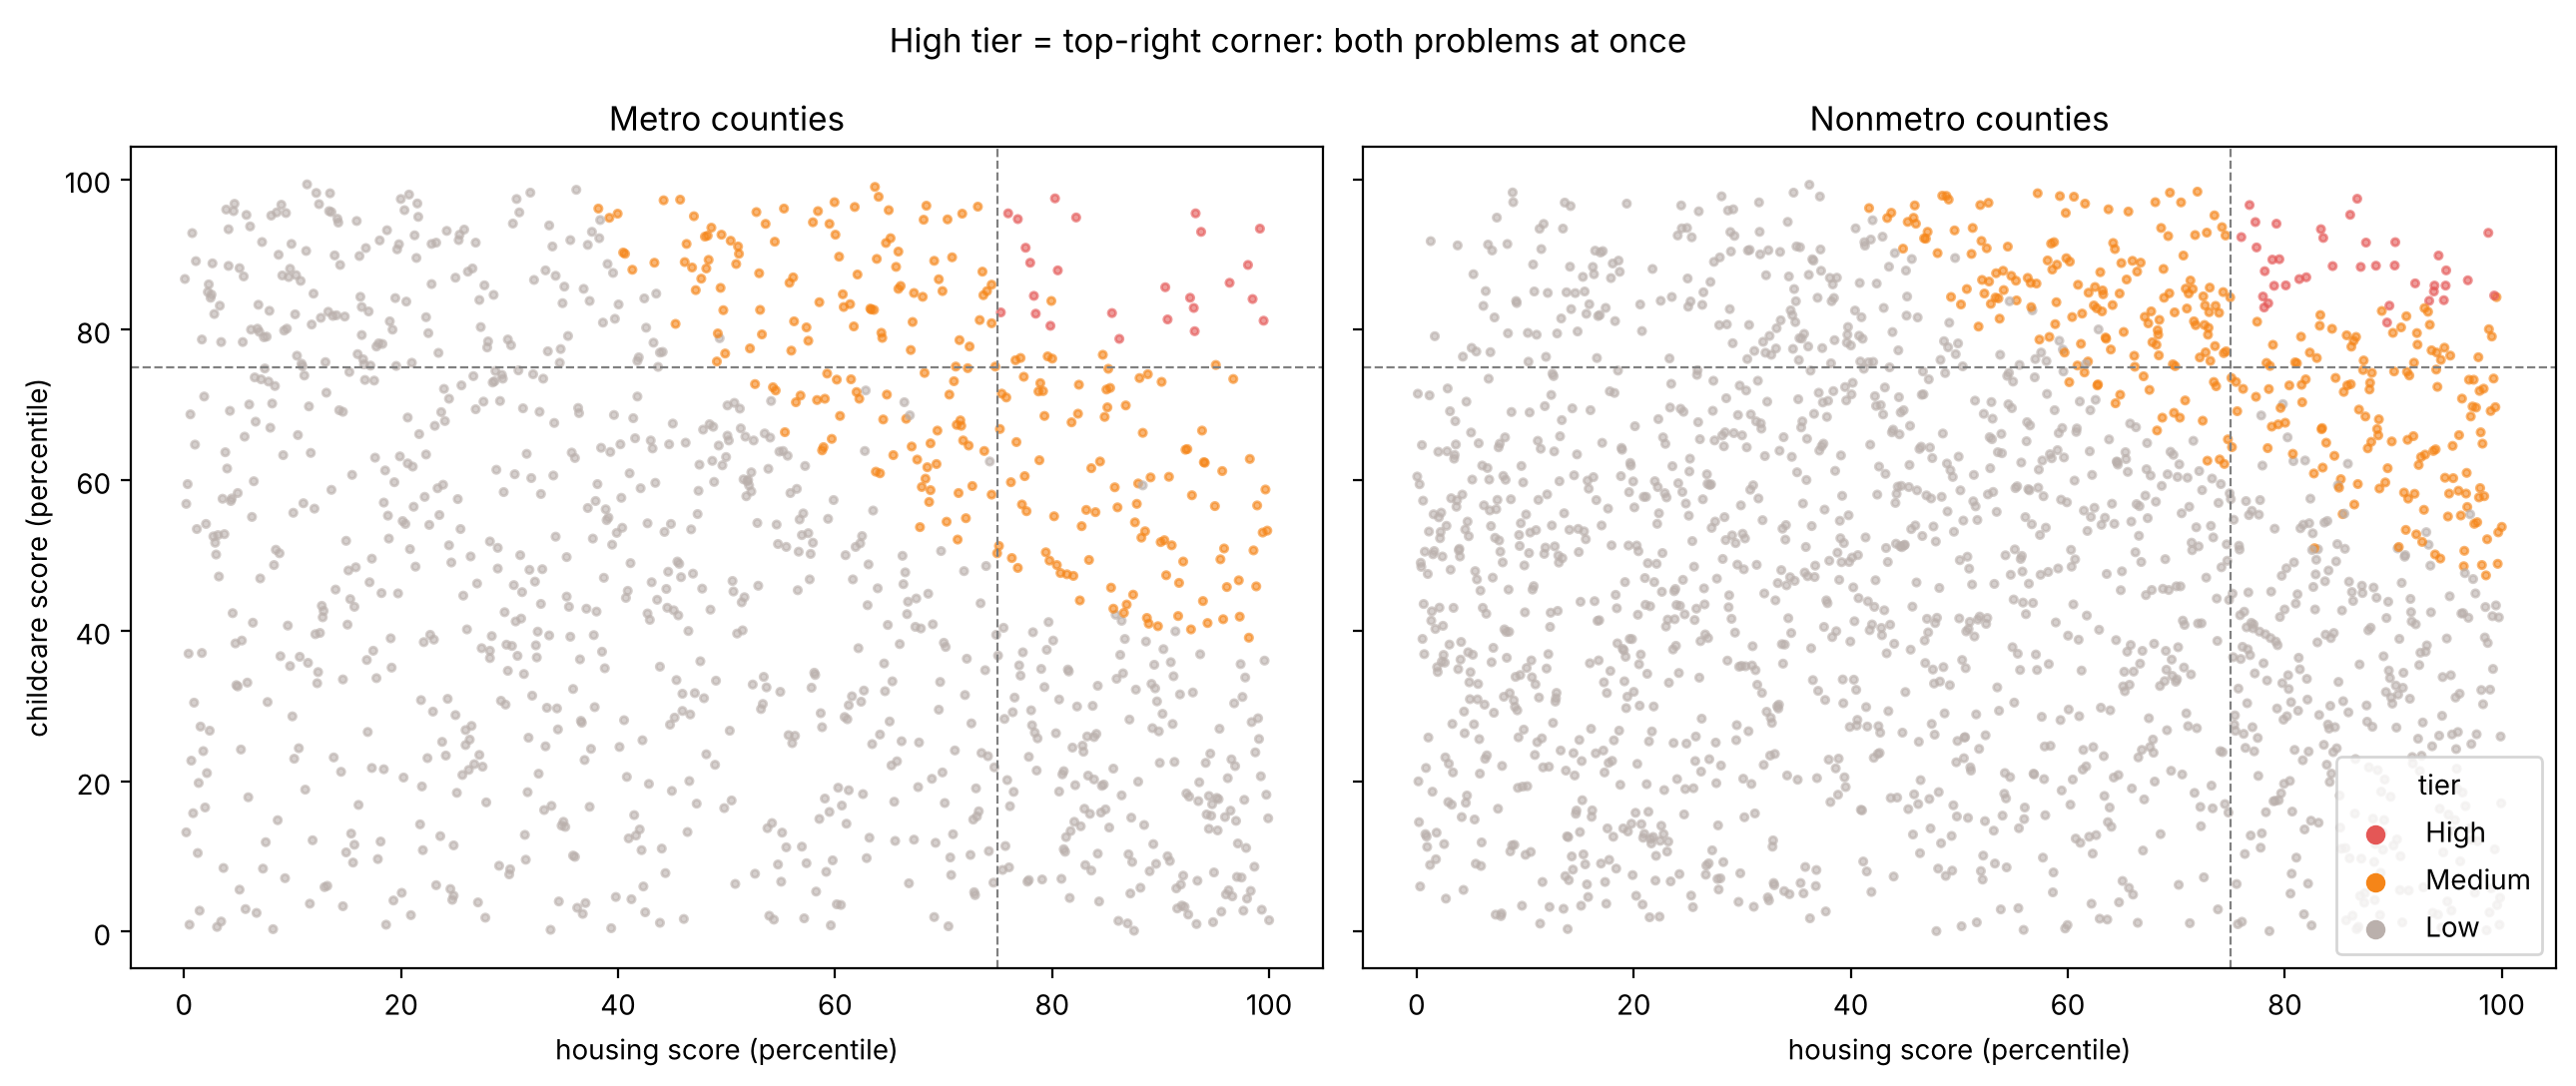

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
colors = {"High": "#E45756", "Medium": "#F58518", "Low": "#BAB0AC"}
for ax, g in zip(axes, ("Metro", "Nonmetro")):
    sub = s[s["group"] == g]
    ax.scatter(sub["housing_score"], sub["childcare_score"], s=7, alpha=0.6, c=sub["tier"].map(colors))
    ax.axvline(75, color="gray", lw=0.8, ls="--"); ax.axhline(75, color="gray", lw=0.8, ls="--")
    ax.set_title(f"{g} counties"); ax.set_xlabel("housing score (percentile)")
axes[0].set_ylabel("childcare score (percentile)")
for t, c in colors.items():
    axes[1].scatter([], [], c=c, label=t)
axes[1].legend(title="tier", loc="lower right")
fig.suptitle("High tier = top-right corner: both problems at once")
fig.tight_layout()
fig.savefig(FIG / "02_tiers.png", dpi=150)
plt.show()

## 7. Sanity check on places we know

In [13]:
check = ["26163", "26049", "26125", "26099", "26161"]  # Wayne, Genesee, Oakland, Macomb, Washtenaw (MI)
s[s["GEOID"].isin(check)][["county_name", "group", "rank_in_group", "childcare_score", "housing_score",
                           "combined_score", "tier", "stable_share", "college_county"]].round(1)

,county_name,group,rank_in_group,childcare_score,housing_score,combined_score,tier,stable_share,college_county
1257,Genesee County,Metro,955,23.4,24.1,23.8,Low,0.0,False
1282,Macomb County,Metro,197,77.2,56.0,65.7,Medium,0.9,False
1295,Oakland County,Metro,543,40.1,51.5,45.4,Low,0.0,False
1313,Washtenaw County,Metro,838,10.0,90.6,30.1,Low,0.0,True
1314,Wayne County,Metro,562,34.1,58.2,44.5,Low,0.0,False


In [14]:
mi = s[s["USPS"] == "MI"].sort_values("combined_score", ascending=False)
print(f"Michigan: {len(mi)} counties scored; tiers:")
print(mi["tier"].value_counts())
mi[["county_name", "group", "rank_in_group", "childcare_score", "housing_score", "combined_score",
    "tier", "tier_uncertain", "stable_share"]].head(10).round(1)

Michigan: 82 counties scored; tiers:
tier
Low       60
Medium    22
Name: count, dtype: int64


,county_name,group,rank_in_group,childcare_score,housing_score,combined_score,tier,tier_uncertain,stable_share
1275,Lake County,Nonmetro,104,84.3,75.0,79.4,Medium,False,1.0
1235,Allegan County,Nonmetro,151,65.2,89.9,76.3,Medium,False,1.0
1237,Antrim County,Nonmetro,174,86.7,65.4,75.2,Medium,False,0.8
1249,Chippewa County,Nonmetro,195,84.8,64.8,74.0,Medium,False,1.0
1250,Clare County,Nonmetro,206,85.2,63.2,73.3,Medium,False,0.9
1301,Otsego County,Nonmetro,222,59.7,89.3,72.8,Medium,False,0.9
1297,Ogemaw County,Nonmetro,240,82.4,63.2,72.0,Medium,False,0.9
1252,Crawford County,Nonmetro,241,79.7,65.2,72.0,Medium,False,1.0
1248,Cheboygan County,Nonmetro,255,76.5,66.1,71.0,Medium,False,0.9
1268,Iron County,Nonmetro,262,78.8,63.5,70.7,Medium,False,0.7


## 8. Save scores for the map

In [15]:
out_cols = ["GEOID", "USPS", "county_name", "group", "rucc_2023", "kids_under5", "screened_out",
            "childcare_score", "childcare_score_low", "childcare_score_high", "housing_score",
            "rent_burden_pctile", "price_to_income_pctile", "provider_rent_pctile", "combined_score", "combined_low", "combined_high",
            "rank_in_group", "tier", "tier_uncertain", "stable_share",
            "rent_burden_eb", "price_to_income", "provider_rent_share", "fmr_2br", "childcare_wage", "wage_imputed",
            "rental_vacancy_rate", "workers_low", "workers_high", "kpw_low_eb", "kpw_high_eb",
            "cbp_withheld_0to2", "pop_change_pct", "pop_trend", "college_share", "college_county", "median_hh_income"]
scores = df[["GEOID", "USPS", "county_name", "group", "rucc_2023", "kids_under5", "screened_out",
             "rental_vacancy_rate", "price_to_income", "cbp_withheld_0to2", "pop_change_pct", "pop_trend",
             "college_share", "college_county", "median_hh_income"]].merge(
    s[[c for c in out_cols if c not in ("USPS", "county_name", "group", "rucc_2023", "kids_under5", "screened_out",
                                         "rental_vacancy_rate", "price_to_income", "cbp_withheld_0to2",
                                         "pop_change_pct", "pop_trend", "college_share", "college_county",
                                         "median_hh_income")]],
    on="GEOID", how="left")[out_cols]
scores.loc[scores["screened_out"], "tier"] = "Not scored"
scores.to_csv(ROOT / "data/processed/county_scores_v1.csv", index=False)
print(f"Saved {len(scores):,} counties to data/processed/county_scores_v1.csv")
scores["tier"].value_counts()

Saved 3,144 counties to data/processed/county_scores_v1.csv


tier
Low           2418
Medium         554
Not scored     109
High            63
Name: count, dtype: int64

## Notes

What to check before the map: do the top counties make sense to you, and does anything in the Michigan list look wrong for reasons the data can't see?